In [ ]:


### observations / thoughts / questions

### 1) correlation increases if I shift f?  corr(f, f) < corr(f, Tf)
### 2) does it matter if mass_f doesn't equal mass_g since we normalize to int=1?
### 3) do we expect corr(f, g) to match distance compted directly from tensors?
### 4) what is a possible explaination for why correlation would increase with heterogeneity
###    either ||g|| increases or corr decreases. (I think it's the correlation)

### 5) is there a simple function we can use to see if we are getting the correct value for f =/= g ?
###    like a Gausssian or something



In [1]:
### standard libraries
import time
import numpy as np
import matplotlib.pyplot as plt
import importlib
### other
import mrcfile

### my modules
from fast_volume_align_ot import utils, plots, transforms, signals, fle_3d, alignments, distances

In [2]:
# vol_a_file = 'Data/het_models/0.mrc'
# vol_b_file = 'Data/het_models/0.mrc'

# vol_a_file = 'Data/het_models/5.mrc'
# vol_b_file = 'Data/het_models/5.mrc'

# with mrcfile.open(vol_a_file, permissive=True) as mrc:
#     f = mrc.data
#     dx_f = mrc.voxel_size.x  # voxels are 1x1x1
#     mrc.close

# with mrcfile.open(vol_b_file, permissive=True) as mrc:
#     g = mrc.data
#     dx_g = mrc.voxel_size.x
#     mrc.close   


# s = 1 # integer scale factor for downsample
# ds = dx_f * s
# # ds = 1

# f = transforms.block_average_downsample(f, s) 
# g = transforms.block_average_downsample(g, s) 
# # g = transforms.translate_3d(g, 5, 5, 5)

# f = np.pad(f, pad_width=((0, 1), (0, 1), (0, 1)))  ### zero-pad to make odd size
# g = np.pad(g, pad_width=((0, 1), (0, 1), (0, 1)))  

# f = signals.Signal(f, d=3, dx=1).preprocess_signals()[0] 
# g = signals.Signal(g, d=3, dx=1).preprocess_signals()[0]



N = 65
d = 3
sigma= 5

f = utils.gaussian_3d(N, sigma=sigma)
g = utils.gaussian_3d(N, sigma=sigma)

f = signals.Signal(f, d=3, dx=1).preprocess_signals()[0] 
g = signals.Signal(g, d=3, dx=1).preprocess_signals()[0]

print(f.shape)
print(np.amin(f), np.amax(f), np.sum(f))
print(np.amin(g), np.amax(g), np.sum(g))
print('\n')

(65, 65, 65)
0.0 0.0005079490911606183 1.0000000000000002
0.0 0.0005079490911606183 1.0000000000000002




In [3]:
M = f.shape[0]   # grid size LxLxL
N = f.shape[0]
max_l = M//2

z = np.linspace(-1, 1, N, endpoint=False)
thetas = np.linspace(0, np.pi, N, endpoint=True)
phis = np.linspace(0, 2*np.pi, N, endpoint=False)


dVsphere = (z[1]-z[0])*(thetas[1]-thetas[0])*(phis[1]-phis[0]) 
# dVsphere = (z[1]-z[0])**3
# dVsphere = (2/(f.shape[0]))**3


sinthetas = np.sin(thetas)[np.newaxis, np.newaxis, :]
# sinthetas = np.ones(M)

f_t = transforms.Transform(f, d=3).inverse_cdf_transform()[0]
g_t = transforms.Transform(g, d=3).inverse_cdf_transform()[0]

fle = fle_3d.FLEBasis3D(M, M, 1e-6, max_l=max_l, mode="complex", force_real="True")

t = time.time()
c = alignments.fast_rotational_correlation(f_t, g_t, fle)
print("compute correlation: ", time.time() - t, '\n')

print(dVsphere)

correlation R=0:  4.18427237474886
all correlation:  4.18427237474886
compute correlation:  1.0726549625396729 

0.00014600006510487218


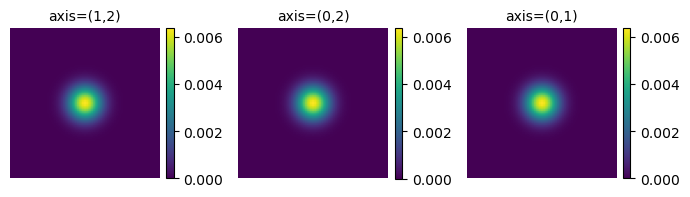

True

In [4]:
plots.orthogonal_2D_projection_plot(f)

np.allclose(f,g)

In [5]:
# f_t_norm = np.linalg.norm(f_t * sinthetas)
# g_t_norm = np.linalg.norm(g_t * sinthetas)


f_t_norm = np.sqrt(np.sum(f_t**2 * sinthetas))
g_t_norm = np.sqrt(np.sum(g_t**2 * sinthetas))



print(f_t_norm**2 * dVsphere, g_t_norm**2 * dVsphere)

6.609444483756598 6.609444483756598


In [6]:
# np.sum((f_t * g_t) * sinthetas**2) * dVsphere

np.sum(f_t * g_t * sinthetas) * dVsphere

6.609444483756598

In [7]:
np.amax(c), np.amin(c)

(4.184272374748861, 4.184272374748861)

In [8]:
2 * np.amax(c) 

8.368544749497723

In [11]:
f_t_norm**2 * dVsphere

6.609444483756598

In [12]:
# ( (f_t_norm**2 + g_t_norm**2) * dVsphere*4.288/6.681 - 2*np.amax(c) ) 

( (f_t_norm**2 + g_t_norm**2) * dVsphere - 2*np.amax(c) ) 

4.850344218015474

In [13]:
z = ( (f_t_norm**2 + g_t_norm**2) * dVsphere - 2*c ) 
np.amin(z)

4.850344218015474

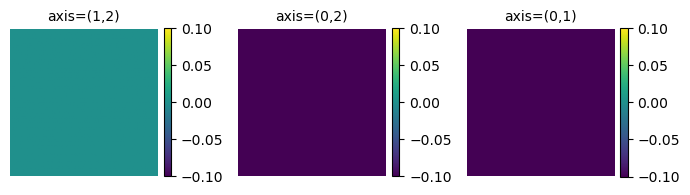

In [14]:
plots.orthogonal_2D_projection_plot(f - g)

In [ ]:
### compute the distance from tensors, the expanded terms 
### and then compare to the correlation from FRC
### skip the 1/4pi average?

sinthetas = np.sin(thetas)[np.newaxis, np.newaxis, :]

### EV: if I use this they match, so not propogating the sin(theta) correctly?
# sinthetas = np.ones(M)



dS = (thetas[1]-thetas[0])*(phis[1]-phis[0])

# d_total = np.sum((f_t*sinthetas - g_t*sinthetas)**2) 


### EV: probably should be the mean ?
# d_slices = np.mean((f_t*sinthetas - g_t*sinthetas)**2, axis=1)
# d_total = np.mean(d_slices)
# d_total = np.mean((f_t*sinthetas - g_t*sinthetas)**2)  # same thing

In [ ]:
# np.linalg.norm(f_t * sinthetas)**2 * dS

In [ ]:
# dS * ( np.linalg.norm(f_t * sinthetas)**2 + np.linalg.norm(g_t * sinthetas)**2 - 2*np.sum( (f_t * g_t)*sinthetas ) )


dS * ( np.linalg.norm(f_t * sinthetas)**2 + np.linalg.norm(g_t * sinthetas)**2 - 2*np.sum( (f_t * g_t)*sinthetas**2 ) ) 


In [ ]:
# np.mean(f_t * g_t) * dS

In [ ]:
np.allclose(np.linalg.norm(f_t * sinthetas)**2 , np.sum(f_t**2 * sinthetas**2))

In [ ]:
np.linalg.norm(f_t*sinthetas - g_t*sinthetas)**2 * dS

In [ ]:
plots.orthogonal_2D_slice_plot(f)
plots.orthogonal_2D_slice_plot(f_t)

In [ ]:
plt.plot(f_t[0, :, 0], 'p--')

In [ ]:
np.linalg.norm(f_t[0, :, 0])**2

In [ ]:
2*np.pi*sigma*np.sqrt(2*np.pi)

In [ ]:
47.24882983716725 / 16.38572001466551

In [ ]:
def fibers_allclose(arr, atol=1e-8):
    ref = arr[:, 0, :]  # reference slice for each fiber
    return np.all(np.isclose(arr, ref, atol=atol))



fibers_allclose(f_t, atol=1e-5)

In [ ]:
# plt.plot(f_t[0, :, 0][1:-1], 'p--')
# plt.plot(f_t[10, :, 0][1:-1], 'p--')
# plt.plot(f_t[10, :, 10][1:-1], 'p--')
# plt.plot(f_t[32, :, 32][1:-1], 'p--')
# plt.plot(f_t[0, :, 10][1:-1], 'p--')
# plt.plot(f_t[-1, :, -1][1:-1], 'p--')
# plt.show()
plt.plot(f_t[0, :, 0], 'p--')
plt.plot(f_t[10, :, 0], 'p--')
plt.plot(f_t[10, :, 10], 'p--')
plt.plot(f_t[32, :, 32], 'p--')
plt.plot(f_t[0, :, 10], 'p--')
plt.plot(f_t[-1, :, -1], 'p--')
plt.show()

In [ ]:
np.linalg.norm(f_t[-1, :, -1])**2

In [ ]:
47.24882983716725 / 16.38572001466551

In [ ]:
np.allclose(f_t[0, :, 0], f_t[0, :, 1]), np.allclose(f_t[0, :, 0], f_t[-1, :, 32]), 

In [ ]:
ref = f_t[0,:,0]
for idx1 in range(N):
    for idx2 in range(N):
        t = np.allclose(ref, f_t[idx1, :, idx2])
        if t == True:
            next
        else:
            print(idx1, idx2)